# Simulação de Epidemias em Redes
**Autores:** _Rafael Gontijo_, _Rudá Brandão_ &nbsp;|&nbsp; **Data:** _24/11/2026_ &nbsp;|&nbsp; **Prazo:** 24/11/2026

**Resumo (opcional, 3–4 linhas):** _preencher ao final._

## Guia de uso do notebook (célula de estudo — removida no PDF)

**Convenção de tags** (View → Cell Toolbar → Tags):
| Tag | Efeito na exportação final |
|---|---|
| `study` | célula **removida** (rascunhos, anotações, checklists) |
| `hide-code` | código **oculto**, saída (figuras/tabelas) mantida |
| _(sem tag)_ | aparece normalmente |

**Orçamento de páginas (PDF):** 1 página por questão, sem contar anexos. Sugestão: Métodos + Declaração de IA ≤ 1 pág. (confirmar com o professor se contam); Q1, Q2, Q3 ≤ 1 pág. cada; código vai em anexo.

**Regras de ouro**
- Rodar sempre com *Restart & Run All* antes de exportar.
- Resultados pesados vão para `results/` (cache); o notebook relê do disco se existir.
- Toda figura: eixos rotulados, unidades, legenda, `savefig` em `figs/`.
- Nenhuma semente "solta": tudo derivado de `SEED_BASE` (seção 0).

**Checklist global**
- [ ] Declaração de IA preenchida
- [ ] Sementes informadas
- [ ] ⟨k⟩, ⟨k²⟩ medidos para cada rede (ER, SF)
- [ ] Declarado: rede fixa ou várias realizações
- [ ] 100 execuções por conjunto de parâmetros, T ≥ 500
- [ ] Extintas (fração + tempo típico), ρ(t) condicionado + faixa p10–p90 em cada caso
- [ ] Opcionais (+10%): Q1(d), média incondicional, 2.4

## Declaração de contribuição de IA
> _Obrigatório. Descrever **o que** a IA fez (ex.: sugestão de estrutura, depuração, otimização do simulador, revisão de texto), **em quais partes** e **como foi verificado/validado** pela dupla. Citar ferramenta/modelo._

- Ferramenta(s) usada(s): Claude
- Contribuição de LLM: Geração de template para o trabalho, revisão de texto e auxílio de pesquisa
- Validação feita pelos autores: Todas as implementações e contas foram feitas a mão

## 0. Configuração e reprodutibilidade

In [1]:
# Imports
import os, json, time, pickle, platform
import numpy as np
import scipy
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
# TODO: demais imports (ex.: scipy.sparse.linalg, numba, pandas, tqdm)

In [2]:
# Parâmetros globais fixados pelo enunciado
N = 10_000				# número de nós
T = 500            		# horizonte (mínimo)
N_RUNS = 100       		# execuções por rede por conjunto de parâmetros
N_SEEDS_INFECTED = 5	# número inicial de infectados
T_AVG = 100        		# janela da prevalência quase-estacionária
EPS = 1e-3         		# alternativa do critério de extinção (Q3)

SEED_BASE = 42   		# SEED inicial para as simulações
# TODO: política de sementes (ex.: np.random.SeedSequence(SEED_BASE).spawn(...) por rede / por execução)

# Organização de arquivos
for d in ["figs", "results"]:
    os.makedirs(d, exist_ok=True)

In [3]:
# Estilo de figuras
plt.rcParams.update({
    # Tamanho e resolução
    "figure.figsize": (6.5, 2.4),     # largura útil da página; ajuste a altura por figura
    "figure.dpi": 110,                # exibição no notebook
    "savefig.dpi": 300,               # arquivo salvo / PDF final
    "savefig.bbox": "tight",          # corta margens em branco
    "figure.constrained_layout.use": True,  # evita rótulos sobrepostos

    # Fontes (legíveis em figura pequena)
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "mathtext.fontset": "cm",         # símbolos como β, μ, ρ* no estilo LaTeX
    "font.family": "serif",           # combina com o texto do PDF

    # Linhas e marcadores
    "lines.linewidth": 1.5,
    "lines.markersize": 4,

    # Eixos e grade
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,

    # Legenda
    "legend.frameon": False,

    # Vetorial limpo no PDF (fontes editáveis, sem Type 3)
    "pdf.fonttype": 42,
})

In [4]:
# Registro de ambiente (vai para o relatório)
print("Python", platform.python_version(), "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| networkx", nx.__version__)
print("SEED_BASE =", SEED_BASE)

Python 3.14.3 | numpy 2.5.5 | scipy 1.18.1 | networkx 3.7
SEED_BASE = 42


### 0.1 Funções comuns (esqueleto — implementar)

In [25]:
# ---------- Avaliação de redes ----------
def medir_rede(G: nx.Graph):
    '''Retorna dict: <k>, <k^2>, k_min, k_max, n_componentes'''
    degrees = np.array(dict(G.degree).values())
    k_1 = np.mean(degrees)
    k_2 = np.mean(degrees ** 2)
    k_min = np.min(degrees)
    k_max = np.max(degrees)
    comps = nx.number_connected_components(G)

    return {
        '<k>': k_1,
        '<k^2>': k_2,
        'k_min': k_min,
        'k_max': k_max,
        'n_comps': comps
    }        

# ---------- Simulação SIS ----------
def step_sis(G: nx.Graph, beta: float, mu: float, rng):
	'''
	Executa um passo do SIS para a rede, retorna o número de sussetiveis e infectados após a atualização 
	'''

	states = nx.get_node_attributes(G, 'Estado')
	next_states = states.copy()

	for no, estado in states.items():
		if estado == 'I':
			if rng.random() < mu:
				next_states[no] = 'S'
				continue
		
		vizinhos_inf = sum(1 for vis in G.neighbors(no) if states[vis] == 'I')
		if vizinhos_inf > 0:
			if rng.random() < 1 - (1 - beta) ** vizinhos_inf:
				next_states[no] = 'I'

	nx.set_node_attributes(G, next_states, 'Estado')

	return sum(1 for s in next_states.values() if s == 'S'), sum(1 for s in next_states.values() if s == 'I')


def simular_sis(G: nx.Graph, beta: float, mu: float, T: int, rng, imunizados=None, n_inicial=N_SEEDS_INFECTED):
	'''
	SIS discreto síncrono (estado do passo anterior).
	Retorna: serie I(t) (len T+1), t_extincao (ou None), graus dos sementes iniciais.
	'''
	if imunizados is not None:
		G.remove_nodes_from(imunizados)

	nx.set_node_attributes(G, {n:"S" for n in G.nodes}, "Estado")
	infected_seeds = rng.choice(list(G.nodes), size=min(n_inicial, G.number_of_nodes()), replace=False)
	nx.set_node_attributes(G, {n:'I' for n in infected_seeds}, 'Estado')
	
	infected_history = np.zeros(T+1)
	infected_history[0] = len(infected_seeds)

	for t in range(1, T+1):
		_, I = step_sis(G, beta, mu, rng)
		if I == 0:
			return infected_history, t

		infected_history[t] = I

	return infected_history, None

# ---------- Estatísticas ----------
def resumir_execucoes(series, tempos_ext, populacao, T_avg=T_AVG):
	'''
	A partir das séries I(t) de várias execuções, retornar:
	frac_extintas, tempo_tipico_extincao, rho_cond(t) (média só dos sobreviventes),
	p10(t), p90(t), rho_estacionario (média dos últimos T_avg passos nos sobreviventes),
	e (opcional) média incondicional.
	'''
	rho_mtx = np.array(series).T / populacao
	nao_ext_mask = rho_mtx[-1] != 0
	frac_extintas = np.mean(nao_ext_mask)

	tempos_ext_limpo = [t for t in tempos_ext if t is not None]
	tempo_tipico_extincao = np.mean(tempos_ext_limpo)
	
	rho_cond = np.mean(rho_mtx[:, nao_ext_mask], axis=1)
	p10, p90 = np.quantile(rho_mtx[:, nao_ext_mask], [.1, .9], axis=1)

	rho_est = np.mean(rho_cond[-T_avg:])
	rho_geral = np.mean(rho_mtx[-T_avg:, :])

	return {
		'frac_extintas': frac_extintas,
		'tempo_tipico_extincao': tempo_tipico_extincao,
		'rho_cond_media_serie': rho_cond,
		'rho_cond_p10_serie': p10,
		'rho_cond_p90_serie': p90,
		'rho_cond_media_tavg': rho_est,
		'rho_geral_media_tavg': rho_geral,
		'populacao': populacao,
		'n_amostras': rho_mtx.shape[1],
		'tam_serie': rho_mtx.shape[0],
		'tavg': T_avg
	}

def rodar_lote(G, beta, mu, rng_seed, n_runs=N_RUNS, T=T, imunizados=None, n_inicial=N_SEEDS_INFECTED, cache_key=None):
	'''
	Roda n_runs execuções; usa cache em results/ se cache_key existir.
	Retorna as séries completas.
	'''
	# TODO: implementar cache em results/

	rng = np.random.default_rng(rng_seed)
	series, tempos = list(), list()
	for _ in range(n_runs):
		s, t = simular_sis(G, beta, mu, T, rng, imunizados, n_inicial)
		series.append(s)
		tempos.append(t)

	return series, tempos

# ---------- Utilidades de saída ----------
def salvar_fig(fig, nome):
    fig.savefig('figs/' + nome + '.png')

def plot_rho_cond(resumo, ax, rotulo):
	'''ρ(t) condicionado + faixa p10–p90.'''
	ax.plot(resumo['rho_cond_media_serie'], label='média')
	ax.plot(resumo['rho_cond_p10_serie'], label='quantil 10%', ls='--', lw=1.5)
	ax.plot(resumo['rho_cond_p90_serie'], label='quantil 90%', ls='--', lw=1.5)
	ax.fill_between(np.arange(resumo['tam_serie']), resumo['rho_cond_p10_serie'], resumo['rho_cond_p90_serie'], alpha=0.2)
	ax.set_title(rotulo)
	ax.set_ylabel(r'Prevalência $\rho (t)$')
	ax.set_xlabel(r'Tempo $t$')

	return

c:\Users\rudab\Documents\FGV\2026_2\NS-2026\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\rudab\Documents\FGV\2026_2\NS-2026\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


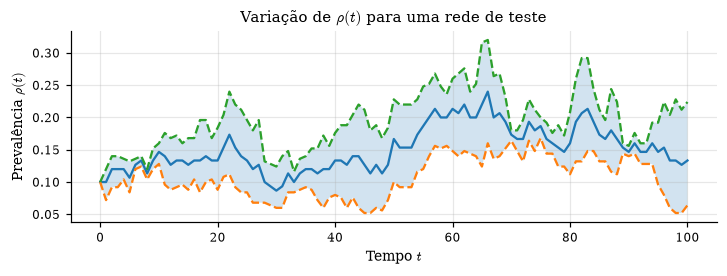

In [29]:
# Testes rápidos (sanidade) — antes de rodar em escala
# TODO: casos triviais (beta=0 -> extinção; mu=0 -> sem recuperação; rede pequena conferida à mão)

N_teste, p_teste = 50, 1/25
g_teste = nx.erdos_renyi_graph(N_teste, p_teste)
series_teste, tempos_teste = rodar_lote(g_teste, 0.1, 0.1, 0, 3, 100)
resumo_teste = resumir_execucoes(series_teste, tempos_teste, N_teste, 5)

f, a = plt.subplots()
plot_rho_cond(resumo_teste, a, r'Variação de $\rho(t)$ para uma rede de teste')
salvar_fig(f, 'teste_sanidade')

## 1. Métodos
**Modelo.** SIS discreto síncrono, $\Delta t = 1$; suscetível com $m$ vizinhos infectados infecta com prob. $1-(1-\beta)^m$; infectado recupera com prob. $\mu$. $N=10^4$, 5 infectados iniciais sorteados entre não imunizados.

**Redes geradas.** _Descrever método, sementes, e declarar: rede fixa **ou** várias realizações (ex.: 10 redes × 10 execuções)._

**Execuções e observáveis.** 100 execuções por conjunto de parâmetros; $T = 500$; execução extinta se $I(t)=0$ para algum $t\le T$; prevalência estacionária = média de $\rho$ nos últimos 100 passos **apenas** nas execuções sobreviventes; faixa p10–p90.

**Reprodutibilidade.** Semente base, versões de bibliotecas, tempo de execução total: _preencher._

| Rede | Método | N | ⟨k⟩ | ⟨k²⟩ | k_max | λ₁ | Semente |
|---|---|---|---|---|---|---|---|
| ER | | | | | | | |
| Livre de escala (γ=2,5) | | | | | | | |

In [7]:
# TODO: tabela de redes (preenchida a partir de medir_rede) — exibir como DataFrame/tabela formatada

## 2. Questão 1 — Rede aleatória (Erdős–Rényi)
**Parâmetros:** $\langle k\rangle=20$, $\beta=0{,}02$; (a) $\mu=0{,}1$; (b) $\mu=0{,}3$; (c) $\mu=0{,}5$; (d, opcional) $\mu=0{,}4$.

### 2.0 Geração da rede ER

In [8]:
# TODO: gerar rede ER, medir <k>, <k^2>, k_max, lambda_1; registrar na tabela de Métodos

### 2.1 Experimento
**Previsões antes de simular** (campo médio homogêneo):

| Caso | μ | $R_0=\beta\langle k\rangle/\mu$ | $\rho^*$ previsto |
|---|---|---|---|
| (a) | 0,1 | | |
| (b) | 0,3 | | |
| (c) | 0,5 | | |
| (d, opc.) | 0,4 | | |

In [9]:
# TODO: calcular R0 e rho* teóricos (antes das simulações)

In [10]:
# TODO: rodar lotes para (a), (b), (c) [e (d)]; salvar em results/

**Resultados por caso** (fração de extintas, tempo típico de extinção, $\rho^*$ simulado vs. previsto):

| Caso | Extintas até T | Tempo típico de extinção | $\rho^*_{sim}$ (sobreviventes) | $\rho^*_{teo}$ |
|---|---|---|---|---|
| (a) | | | | |
| (b) | | | | |
| (c) | | | | |

In [11]:
# TODO: tabela de resultados + figura: rho(t) condicionado (média + faixa p10–p90), um painel por caso, com linha de rho* teórico
# (opcional) média incondicional sobreposta

**Discussão.**
- Comparação simulação × campo médio: _…_
- Tempo discreto: _…_
- Correlações entre vizinhos: _…_
- Tamanho finito e extinções precoces com 5 sementes: _…_
- (opcional) Caso crítico (d), $R_0=1$: decaimento algébrico, dependência de $T$: _…_
- (opcional) Por que a média incondicional mistura dois comportamentos: _…_

### 2.2 Demonstração (campo médio homogêneo)
Mapa: $\rho_{t+1}=g(\rho_t)=\rho_t-\mu\rho_t+\beta\langle k\rangle\rho_t(1-\rho_t)$, $R_0=\beta\langle k\rangle/\mu$.

**(1) Pontos fixos.**
_Demonstração:_ …

**(2) Estabilidade.** $g'(0)$, $g'(\rho^*)$, condição $\mu(R_0-1)<2$ e verificação nos casos da Q1.
_Demonstração:_ …

**(3) Crescimento a partir de poucos infectados.** Se $R_0>1$ e $0<\rho_t<\rho^*$ então $\rho_{t+1}>\rho_t$.
_Demonstração:_ …

In [12]:
# TODO: iterar o mapa com os parâmetros da Q1 e verificar convergência a rho*
# TODO: verificar numericamente mu(R0-1) < 2 em cada caso
# Figura: trajetórias rho_t (várias condições iniciais) com rho* marcado

**Conclusão numérica:** _a doença se estabelece? Em quais casos? Comentar relação com a simulação estocástica._

## 3. Questão 2 — Rede livre de escala
**Parâmetros:** $\gamma=2{,}5$, $N=10^4$, $\langle k\rangle\approx20\ (\pm10\%)$, $\beta=0{,}01$; (a) $\mu=0{,}1$; (b) $\mu=0{,}2$; (c) $\mu=0{,}3$.

### 3.0 Geração da rede

In [13]:
# TODO: escolher k_min (8–9) e k_max ~ sqrt(N<k>) ~ 450; gerar rede (configuração erased ou Chung–Lu)
# TODO: reportar <k>, <k^2>, k_max, lambda_1; checar <k> em [18, 22]
# Figura: P(k) em escala log-log com ajuste/linha de referência k^-gamma

**Rede gerada:** ⟨k⟩ = …, ⟨k²⟩ = …, k_max = …, λ₁ = …  _(método, sementes, tratamento de laços/arestas múltiplas)_

### 3.1 Experimento

In [14]:
# TODO: lotes para (a), (b), (c); registrar tambem o grau dos 5 vértices iniciais de cada execução

| Caso | Extintas até T | Tempo típico de extinção | $\rho^*_{sim}$ (sobreviventes) |
|---|---|---|---|
| (a) | | | |
| (b) | | | |
| (c) | | | |

In [15]:
# TODO: tabela + figura rho(t) condicionado com faixa p10–p90 (um painel por caso)
# TODO: análise: extinção / prevalência final  vs.  grau dos sementes (ex.: grau máximo ou médio das 5 sementes)
#       figura: P(extinção) ou rho* em função do grau das sementes

**Discussão.** Comportamento na média; relação com o grau dos 5 vértices iniciais; papel dos hubs: _…_

### 3.2 Teoria — indicadores de limiar
| Caso | $R_0^{hom}=\beta\langle k\rangle/\mu$ | $R_0^{het}=\beta\langle k^2\rangle/(\mu\langle k\rangle)$ | $R_0^{quenched}=\beta\lambda_1/\mu$ | Previsão hom / het / quenched | Simulação |
|---|---|---|---|---|---|
| (a) | | | | | |
| (b) | | | | | |
| (c) | | | | | |

In [16]:
# TODO: calcular os três indicadores para cada caso

**Discussão.** Onde os indicadores discordam (especialmente em (c)); qual descreve melhor a simulação e por quê: _…_

### 3.3 Comparação com a Questão 1 — curva $\rho^*(\lambda)$, $\lambda=\beta/\mu$
**Protocolo:** fixar $\beta$, variar $\mu$ para varrer $\lambda$ em ER e SF; marcar limiares teóricos de cada rede.

In [17]:
# TODO: definir grade de mu (e portanto lambda) para cada rede; usar mesmo critério de rho* (sobreviventes, últimos 100 passos)
# TODO: rodar varredura (com cache!) para ER e SF

In [18]:
# TODO: figura única: rho*(lambda) para ER e SF
#   + linhas verticais: limiares teóricos (ER: <k>^-1 ; SF: campo médio por grau <k>/<k^2> e/ou quenched 1/lambda_1)

**Discussão.** Diferença de limiar entre topologias; diferença na forma da curva (transição abrupta vs. cauda/queda gradual); efeito de tamanho finito: _…_

### 3.4 Aprofundamento (opcional) — campo médio por grau
$\dfrac{d\rho_k}{dt}=-\mu\rho_k+\beta k(1-\rho_k)\Theta,\quad \Theta=\dfrac{1}{\langle k\rangle}\sum_k kP(k)\rho_k$

**Demonstração:** estado endêmico existe $\iff \beta/\mu>\langle k\rangle/\langle k^2\rangle$.
_…_

**Discussão:** limiar quando $N\to\infty$ para $\gamma\le3$ ($\langle k^2\rangle\to\infty$): _…_

In [19]:
# (opcional) verificação numérica: <k^2> em função de N (ou k_max) para gamma = 2.5, limiar <k>/<k^2> resultante

## 4. Questão 3 — Imunização prévia
**Rede e parâmetros:** rede da Q2, $\beta=0{,}01$, $\mu=0{,}1$. Imunizado = removido da dinâmica. Sementes sorteadas entre não imunizados.

**Critério de extinção:** fração $f$ impede o estado endêmico se, em 100 execuções, nenhuma tem infectados em $t=T=500$ (alternativa: prevalência quase-estacionária $<\varepsilon=10^{-3}$). _Declarar qual critério foi usado._

### 4.0 Estratégias

In [20]:
def imunizar_aleatoria(A, n, rng):
    '''n vértices sorteados uniformemente.'''
    raise NotImplementedError

def imunizar_hubs(A, n):
    '''n vértices de maior grau (definir desempate).'''
    raise NotImplementedError

def imunizar_conhecidos(A, n, rng):
    '''Repetir n vezes: sorteia vértice uniforme, imuniza vizinho aleatório (sem repetição de imunizados).'''
    raise NotImplementedError

def extincao_total(A, f, estrategia, rng_seed, **kw):
    '''Roda 100 execuções com fração f imunizada; retorna se o critério de extinção foi atingido.'''
    raise NotImplementedError

def bissecao_f(A, estrategia, resolucao, rng_seed, f_lo=0.0, f_hi=1.0):
    '''Bisseção do menor f que satisfaz o critério. Registrar histórico de (f, resultado).'''
    raise NotImplementedError

### 4.1 Resultados da bisseção

In [21]:
# TODO: bisseção para (a) aleatória [resolução 0.05], (b) hubs [0.01], (c) conhecidos [0.01]
# TODO: atenção a estocasticidade da própria imunização (aleatória e conhecidos): fixar política (várias realizações de imunização por f?) e declarar

| Estratégia | $f_c$ | $n=f_c N$ | Resolução | Observações |
|---|---|---|---|---|
| (a) Aleatória | | | 0,05 | |
| (b) Hubs | | | 0,01 | |
| (c) Conhecidos | | | 0,01 | |

In [22]:
# TODO: figura: fração de execuções com infecção em T (ou rho*) em função de f, para as 3 estratégias, marcando f_c

### 4.2 Teoria
$\lambda_1(f)$ da rede residual para cada estratégia; checar $\beta\lambda_1(f)/\mu\approx1$.
Para a aleatória: $\kappa(f)=(1-f)\langle k^2\rangle/\langle k\rangle+f$, limiar $\kappa(f)=\mu/\beta$; e homogênea $f=1-1/R_0$.

| Estratégia | $f_c$ (sim) | $\beta\lambda_1(f_c)/\mu$ | $f_c$ (campo médio por grau) | $f_c$ (homogêneo) |
|---|---|---|---|---|
| Aleatória | | | | |
| Hubs | | — | — | — |
| Conhecidos | | — | — | — |

In [23]:
# TODO: calcular lambda_1(f) da rede residual em grade de f, por estratégia
# TODO: determinar f onde beta*lambda_1(f)/mu = 1 e comparar com f_c simulado
# TODO: f_c previsto por kappa(f) = mu/beta e por f = 1 - 1/R0 (aleatória)
# Figura: beta*lambda_1(f)/mu vs f (3 estratégias), linha horizontal em 1, f_c simulados marcados

**Discussão.** A extinção observada coincide com $\beta\lambda_1/\mu\approx1$? Onde e por quê (não)? Comparação aleatória: simulação × campo médio por grau × homogêneo: _…_

### 4.3 Robustez (1–2 parágrafos)
- Tolerância a falhas aleatórias × fragilidade a ataques dirigidos em redes livres de escala (percolação): _…_
- Por que a estratégia dos conhecidos fica entre as outras duas: _…_
- Limiar de percolação (SIR) × limiar do SIS (governado por $\lambda_1$): por que a diferença importa aqui: _…_

## 5. Discussão geral
- Síntese entre as questões (topologia, limiar, papel dos hubs, imunização): _…_
- Limitações: tamanho finito, extinção estocástica/dependência de $T$, escolha entre rede fixa × várias realizações, critério de extinção, resolução da bisseção: _…_
- Possíveis extensões: _…_

## Referências
- _Material de aula; artigos/livros usados (ex.: Pastor-Satorras et al., *Epidemic processes in complex networks*, RMP 2015)._

## Anexo A — Código
> O código completo está neste notebook (`.ipynb`), executável do início ao fim (*Restart & Run All*). Entregar junto ao PDF, com `requirements.txt`.

In [24]:
# Registro final de execução (tempo total, versões, semente)
# TODO: imprimir resumo de reprodutibilidade

## Exportação do PDF final (célula de estudo)

1. *Restart & Run All*; conferir que não há `NotImplementedError`/`TODO` visíveis.
2. Marcar rascunhos com tag `study` e blocos de código com `hide-code` (já pré-marcados neste template).
3. Exportar, por exemplo:
```bash
jupyter nbconvert --to pdf template_trabalho_SIS.ipynb \
  --TagRemovePreprocessor.remove_cell_tags='{"study"}' \
  --TagRemovePreprocessor.remove_input_tags='{"hide-code"}'
```
(alternativa se não houver LaTeX: `--to html`, abrir no navegador e imprimir em PDF; ou `--to webpdf`.)
4. Conferir limite de **1 página por questão** e legibilidade das figuras.
5. Anexar o `.ipynb` + `requirements.txt` + pasta `figs/` (se pedido).

**Checklist final**
- [ ] Declaração de IA visível
- [ ] Todas as tabelas preenchidas
- [ ] Todas as figuras com eixos/legendas/unidades
- [ ] Sementes e versões informadas
- [ ] Opcionais assinalados como tal